# 03 — RFM Segmentation & Customer Lapse Prediction

**Part B**

This notebook uses the actual functions in `src/rfm_segmentation.py` and `src/lapse_model.py`. It covers customer-level RFM features, K-Means clustering, PCA, supervised lapse prediction, model evaluation and saved outputs.

In [1]:
%pip install matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import os, sys

# Find the project root whether this notebook is opened from the project folder or notebooks/.
CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next((p for p in CANDIDATES if (p / "src").is_dir() and (p / "data").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the Instamart project folder (or its notebooks folder).")
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: d:\New folder\Instamart capstone project


In [3]:
import pandas as pd
import numpy as np
from src.rfm_segmentation import compute_rfm, cluster_rfm
from src.lapse_model import build_cohort_and_features, train_and_evaluate

## 1. Load cleaned data and understand RFM
RFM means **Recency**, **Frequency** and **Monetary**. Recency measures how recently a customer ordered; frequency counts completed orders; monetary measures total completed-order spend.

In [4]:
orders = pd.read_csv(PROJECT_ROOT / "data/clean/orders.csv", parse_dates=["order_ts"])
customers = pd.read_csv(PROJECT_ROOT / "data/clean/customers.csv")
print("Orders:", orders.shape, "Customers:", customers.shape)
display(orders.head())

Orders: (12309, 9) Customers: (1200, 5)


,order_id,customer_id,product_id,quantity,order_ts,status,discount_pct,order_amount,delivery_minutes
0,ORD-110093,C0967,P020,1,2025-04-01 07:08:28,completed,15,127.50,19.0
1,ORD-111396,C1117,P036,2,2025-04-01 07:11:59,completed,0,1598.00,25.0
2,ORD-102006,C0194,P009,1,2025-04-01 07:12:43,cancelled,25,21.75,NaN
3,ORD-105921,C0569,P005,2,2025-04-01 07:54:43,completed,10,86.40,33.0
4,ORD-108115,C0776,P012,2,2025-04-01 08:02:58,completed,10,104.40,21.0


## 2. Compute RFM features
The project uses completed orders and a fixed snapshot date of 1 October 2025. The fixed date makes the exercise reproducible.

In [5]:
rfm = compute_rfm()
print("RFM shape:", rfm.shape)
display(rfm.head())
display(rfm[["recency", "frequency", "monetary"]].describe().T)

================ RFM TABLE SUMMARY ================
Total customers with completed orders: 1175 (Reference: 1175)
Recency: min=0, median=19.0, max=180 (Ref: median 19, min 0, max 180)
Frequency: mean=9.46, max=33 (Ref: mean 9.46, max 33)
Monetary: mean=2552.06, max=14766.55 (Ref: mean 2552.06, max 14766.55)

RFM shape: (1175, 4)


,customer_id,recency,frequency,monetary
0,C0001,14,4,512.85
1,C0002,28,7,4644.90
2,C0003,7,22,3644.85
3,C0004,0,5,369.00
4,C0005,147,2,324.00


,count,mean,std,min,25%,50%,75%,max
recency,1175.0,33.558298,38.433705,0.0,6.00,19.0,46.000,180.00
frequency,1175.0,9.455319,8.009971,1.0,3.00,5.0,17.000,33.00
monetary,1175.0,2552.058553,2367.305104,12.0,505.45,2286.5,3751.525,14766.55


## 3. Scale features and evaluate K-Means
RFM features use different units and ranges. StandardScaler puts them on comparable scales before K-Means. The project evaluates K from 2 through 8 using inertia and silhouette score, then selects K=4.

In [6]:
rfm_clustered, segment_profiles, k_evaluation, pca_variance = cluster_rfm(rfm.copy())
display(k_evaluation)
display(segment_profiles)
print("PCA explained variance ratios:", pca_variance)

================ K-MEANS GRID EVALUATION (K=2 to 8) ================
 K  Inertia  Silhouette
 2   1820.8       0.465
 3   1268.2       0.445
 4    743.1       0.526
 5    617.4       0.480
 6    503.2       0.482
 7    408.5       0.416
 8    366.5       0.412

================ PCA EXPLAINED VARIANCE ================
PC1 Variance Ratio: 0.634 (Ref: ~0.634)
PC2 Variance Ratio: 0.218 (Ref: ~0.218)
Total Explained Variance: 0.852 (Ref: ~0.852)

================ SEGMENT PROFILES (K=4) ================
 segment_id  size  mean_recency  mean_frequency  mean_monetary                 segment_name  is_premium                                                                     recommended_action
          0   436     28.862385        3.772936    1057.618234     Steady Moderate Shoppers       False  Personalized category bundle cross-sells to increase basket size and order frequency.
          1   138     24.115942        6.768116    7129.695652  High-Value Premium Shoppers        True Exclusive c

,K,Inertia,Silhouette
0,2,1820.8,0.465
1,3,1268.2,0.445
2,4,743.1,0.526
3,5,617.4,0.480
4,6,503.2,0.482
5,7,408.5,0.416
6,8,366.5,0.412


,segment_id,size,mean_recency,mean_frequency,mean_monetary,segment_name,is_premium,recommended_action
0,0,436,28.862385,3.772936,1057.618234,Steady Moderate Shoppers,False,Personalized category bundle cross-sells to in...
1,1,138,24.115942,6.768116,7129.695652,High-Value Premium Shoppers,True,"Exclusive concierge support, early access to n..."
2,2,419,8.766110,19.403341,3410.020525,Daily Grocery Loyalists,False,"Subscription loyalty perks, free delivery pass..."
3,3,182,109.043956,2.203297,685.992582,Lapsed / At-Risk Occasionals,False,"Win-back discount vouchers, category re-discov..."


PCA explained variance ratios: [0.63427875 0.21803762]


## 4. Inspect segment distribution

In [7]:
segment_counts = rfm_clustered["segment_name"].value_counts().rename_axis("segment").reset_index(name="customers")
display(segment_counts)
print("Premium customers:", int(rfm_clustered["is_premium"].sum()))

,segment,customers
0,Steady Moderate Shoppers,436
1,Daily Grocery Loyalists,419
2,Lapsed / At-Risk Occasionals,182
3,High-Value Premium Shoppers,138


Premium customers: 138


## 5. Visualise customer segments
PCA reduces the three scaled RFM variables to two dimensions for visual inspection. The plot is a visual aid; it does not replace the clustering evaluation.

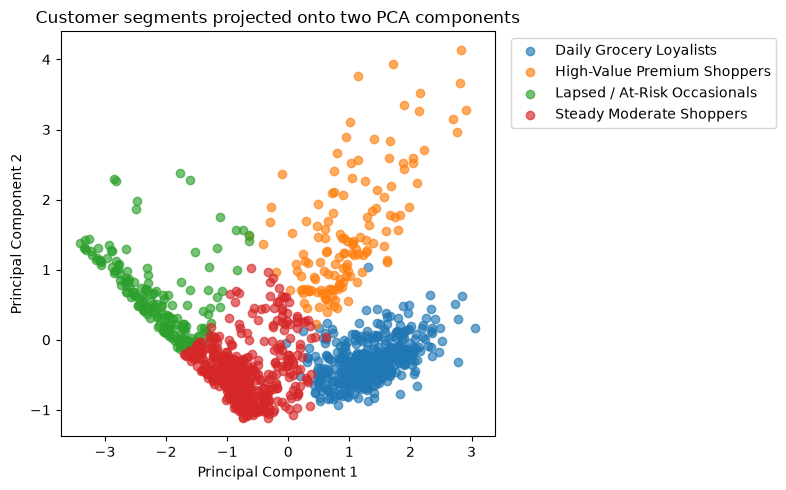

In [8]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
features = rfm_clustered[["recency", "frequency", "monetary"]]
scaled = StandardScaler().fit_transform(features)
coords = PCA(n_components=2, random_state=42).fit_transform(scaled)
plt.figure(figsize=(8, 5))
for label in sorted(rfm_clustered["segment_name"].unique()):
    mask = rfm_clustered["segment_name"].eq(label).to_numpy()
    plt.scatter(coords[mask, 0], coords[mask, 1], label=label, alpha=.65)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer segments projected onto two PCA components")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 6. Build the lapse-prediction cohort and features
This supervised task defines a cohort from customers with at least one completed order before 1 September 2025. A customer is labelled lapsed if they have no completed order during September 2025. This is the project's operational target definition.

In [9]:
lapse_features = build_cohort_and_features()
print("Feature table:", lapse_features.shape)
display(lapse_features.head())
display(lapse_features["lapsed"].value_counts().rename(index={0:"active", 1:"lapsed"}).to_frame("customers"))

Cohort size: 1156 customers (Reference: 1156)
Lapsed customers: 443 / 1156 (38.32%) (Reference: 443, 38.32%)
Feature table: (1156, 13)


,customer_id,recency,frequency,monetary,avg_discount,cancellation_rate,avg_delivery_minutes,favorite_category,lapsed,city,age,gender,tenure_days
0,C0967,77,2,185.1,27.50,0.0000,24.50,Snacks,1,Hyderabad,46,male,458
1,C1117,29,4,4394.7,13.75,0.0000,24.50,Electronics,0,Pune,54,female,528
2,C0569,42,4,553.4,6.25,0.0000,27.75,Grocery,0,Bengaluru,25,male,498
3,C0776,1,20,4428.8,10.50,0.0000,26.95,Dairy,0,Mumbai,39,male,219
4,C1122,5,16,2503.5,11.25,0.1111,28.81,Dairy,0,Mumbai,58,male,580


,customers
lapsed,
active,713
lapsed,443


## 7. Train and evaluate classification models
The project trains and compares Logistic Regression and Random Forest, and includes a class-balance experiment. Review precision, recall, F1 and the confusion matrix. For retention outreach, recall for the lapsed class can be especially important, but precision also matters because outreach has a cost.

In [10]:
model_results = train_and_evaluate(lapse_features)
print("Training/evaluation function completed.")
print("Saved model and metrics should be in outputs/.")

Train set: 924 rows; Test set: 232 rows (Reference: 924 train, 232 test)
Baseline ('always not lapsed'): Accuracy = 61.6%, Lapsed F1 = 0.00

Frequency mean (Train Scaler): 8.1158 vs Full Cohort mean: 8.0285
They differ because the training set is an 80% sample drawn without leaking the 20% test set distribution.

Best Logistic Regression: {'clf__C': 0.1}, CV F1: 0.6372
Best Random Forest: {'clf__max_depth': 5, 'clf__min_samples_leaf': 10}, CV F1: 0.6743

================ MODEL TEST EVALUATION ================
--- Logistic Regression ---
Confusion Matrix:
[[104  39]
 [ 19  70]]
Precision: 0.6422, Recall: 0.7865, F1: 0.7071

--- Random Forest ---
Confusion Matrix:
[[111  32]
 [ 23  66]]
Precision: 0.6735, Recall: 0.7416, F1: 0.7059

================ CLASS-BALANCE EXPERIMENT ================
Balanced training set: 1140 rows ({0: 570, 1: 570})
Unbalanced LR: Precision=0.6422, Recall=0.7865, F1=0.7071
Balanced LR:   Precision=0.5887, Recall=0.9326, F1=0.7217
Recall shifted by +0.1461 (from 

## 8. Inspect generated outputs

In [11]:
for name in ["customer_segments.csv", "lapse_model.joblib", "churn_metrics.json", "churn_predictions.csv", "retention_list.csv"]:
    p = PROJECT_ROOT / "outputs" / name
    print(name, "FOUND" if p.exists() else "not generated by this run")
if (PROJECT_ROOT / "outputs/customer_segments.csv").exists():
    display(pd.read_csv(PROJECT_ROOT / "outputs/customer_segments.csv").head())

customer_segments.csv FOUND
lapse_model.joblib FOUND
churn_metrics.json FOUND
churn_predictions.csv FOUND
retention_list.csv FOUND


,customer_id,recency,frequency,monetary,segment_id,segment_name,is_premium
0,C0001,14,4,512.85,0,Steady Moderate Shoppers,False
1,C0002,28,7,4644.90,1,High-Value Premium Shoppers,True
2,C0003,7,22,3644.85,2,Daily Grocery Loyalists,False
3,C0004,0,5,369.00,0,Steady Moderate Shoppers,False
4,C0005,147,2,324.00,3,Lapsed / At-Risk Occasionals,False


## 9. Interpretation and caveats
- Explain the difference between unsupervised segmentation and supervised prediction.
- Explain why scaling is needed before distance-based clustering.
- Compare precision, recall and F1 rather than relying only on accuracy.
- The September lapse label is specific to this synthetic project dataset and date window; it is not a live prediction of real Instamart customers.

**Part B complete:** RFM segments and lapse-prediction experiments have been run using the project's source code.